# 13 · Noise and sanitation: does the street change within 100 m?
**Know Before You Rent · Team BUTA**

The housing notebooks look *inside* buildings. This one looks at the **street around them**, using NYC 311 complaints about **noise** (loud music, banging, street noise…) and **sanitation** (dirty sidewalks, illegal dumping, rodents, missed collection…).

**Questions**
1. **Within vs between:** do 100 m cells in the same community district differ more than the districts differ from each other?
2. **Neighbor gap:** are cells next to each other more alike than random cells, and how quickly does that fade with distance?
3. **Timing:** when are noise and sanitation complaints made?
4. **Persistence:** are 2025's hotspots still hotspots in 2026?

Then the same tools compare **two real buildings** and write the comparison in plain English, which is what the app shows on the Explore page.

**Method in one line:** every complaint gets x/y coordinates in meters; the city is cut into 100 m × 100 m cells; only cells that contain an apartment building (3+ units, PLUTO) are compared, so parks, highways and empty lots are left out. All code is in `src/street.py` and `src/plots.py`.

**Study window: January 1, 2025 – October 31, 2026.** Year-to-year comparisons use **January–October** of both years, so both cover the same months.

**Data:** [NYC 311 Service Requests](https://data.cityofnewyork.us/d/erm2-nwe9) (`python -m src.download --only 311street`) and [PLUTO](https://data.cityofnewyork.us/d/64uk-42ks) (`--only pluto`). Then `python -m src.street` cleans the complaints and saves the files this notebook reads.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from src import street
from src import plots as P

pd.set_option("display.float_format", "{:,.2f}".format)
if not (street.CLEAN_FILE.exists() and street.BUILDINGS_FILE.exists() and street.FINDINGS_FILE.exists()):
    street.main()                                   # builds everything below (a few minutes)

complaints = pd.read_parquet(street.CLEAN_FILE)
buildings = pd.read_parquet(street.BUILDINGS_FILE)
findings = json.loads(street.FINDINGS_FILE.read_text())
cells = street.cell_table(buildings, complaints)
print(f"{len(complaints):,} complaints · {len(buildings):,} apartment buildings · {len(cells):,} cells of 100 m")

1,339,462 complaints · 172,546 apartment buildings · 27,841 cells of 100 m


## 0. The data after cleaning
Every cleaning step and how many rows it removed (saved to `reports/cleaning_report_street.json`):

In [2]:
report = json.loads(street.CLEANING_FILE.read_text())
pd.DataFrame(report["steps"])[["step", "rows_before", "rows_after", "rows_removed", "detail"]]

,step,rows_before,rows_after,rows_removed,detail
0,load_raw,1813290,1813290,0,14 complaint types
1,drop_duplicate_keys,1813290,1813290,0,duplicate unique_key
2,study_window,1813290,1813290,0,created 2025-01-01 to 2026-10-31
3,known_types,1813290,1813290,0,complaint type listed in config.STREET_TYPES
4,valid_location,1813290,1804815,8475,missing coordinates or outside NYC
5,same_day_repeats,1804815,1339462,465353,"same location, type and descriptor on the same..."
6,done,1339462,1339462,0,"noise=991,461, sanitation=348,001"


In [3]:
by_type = (complaints.groupby(["group", "complaint_type"], observed=True).size()
           .rename("complaints").reset_index().sort_values(["group", "complaints"], ascending=[True, False]))
by_type["share_of_group"] = by_type["complaints"] / by_type.groupby("group")["complaints"].transform("sum")
by_type

,group,complaint_type,complaints,share_of_group
4,noise,Noise - Residential,474378,0.48
5,noise,Noise - Street/Sidewalk,253506,0.26
0,noise,Noise,95777,0.10
1,noise,Noise - Commercial,87007,0.09
6,noise,Noise - Vehicle,67526,0.07
3,noise,Noise - Park,10978,0.01
2,noise,Noise - House of Worship,2289,0.00
7,sanitation,Dirty Condition,117123,0.34
11,sanitation,Missed Collection,72030,0.21
8,sanitation,Illegal Dumping,69667,0.20


## 1. Within vs between: do district averages hide the street?
Each cell's complaints per year are put on a log scale (a few cells have thousands, most have a handful), then the variation is split in two:
- **between districts**: how much district averages differ from the city average;
- **within districts**: how much cells differ from their own district's average.

If the *within* share is large, a district average says little about a particular street.

In [4]:
q1 = pd.DataFrame(findings["q1_within_between"]).T
q1[["cells", "districts", "within_share", "between_share"]]

,cells,districts,within_share,between_share
noise,"27,841.00",59.00,0.72,0.28
sanitation,"27,841.00",59.00,0.82,0.18


The 100 m map of one district shows what that looks like: dark cells next to light ones.

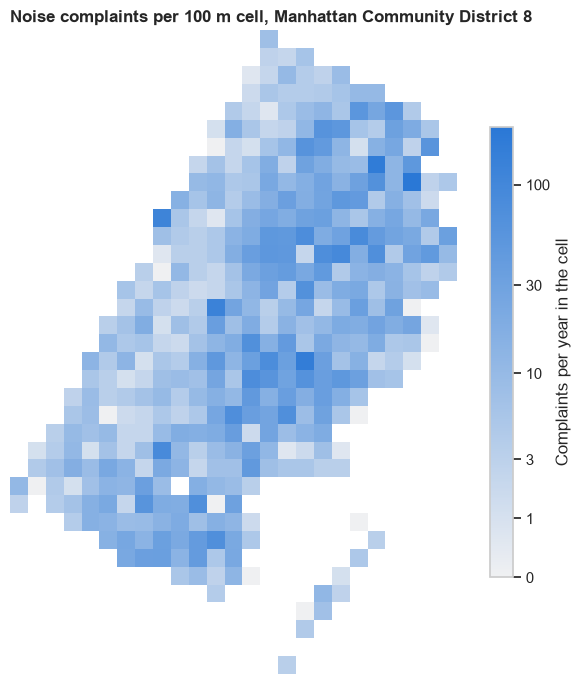

In [5]:
cd = 108   # Manhattan Community District 8 (Upper East Side)
fig = P.plot_cell_map(cells, "noise", cd); P.save(fig, "street_map_noise_mn08")

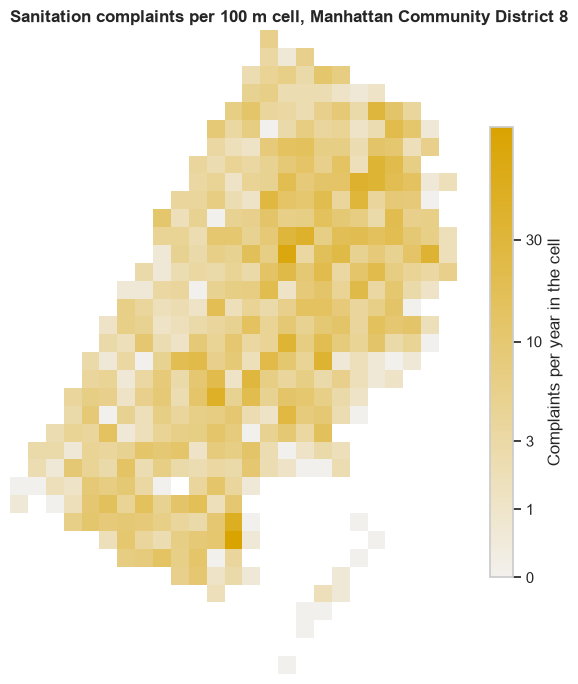

In [6]:
fig = P.plot_cell_map(cells, "sanitation", cd); P.save(fig, "street_map_sanitation_mn08")

## 2. Neighbor gap: are nearby cells more alike?
For each distance from 100 m to 1 km: the average gap between two cells that far apart (with a bootstrap 95% interval, the shaded band). Two reference lines: random cells in the **same district**, and random cells **anywhere** in the city.

If neighbors were identical, the gap at 100 m would be near zero. If location didn't matter at all, it would equal the random line.

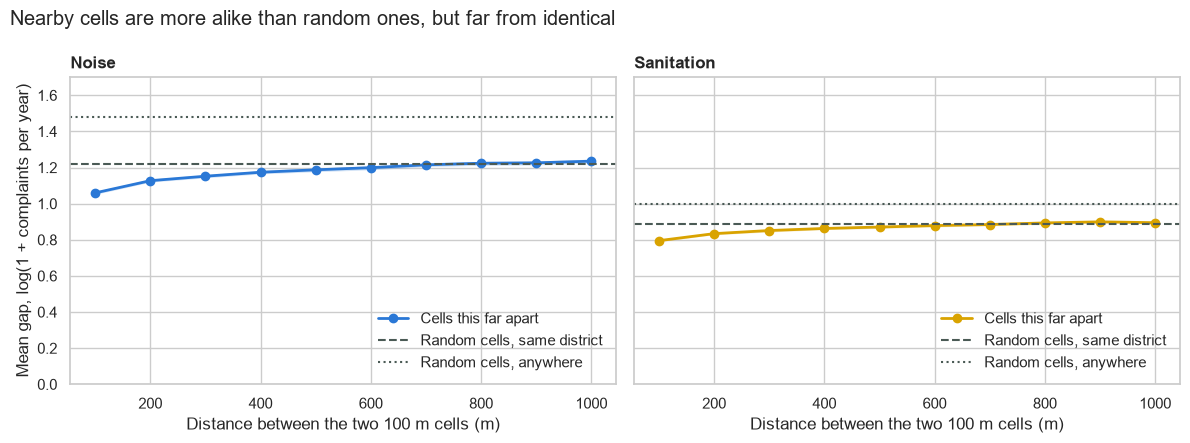

In [7]:
fig = P.plot_neighbor_gaps(findings); P.save(fig, "street_neighbor_gaps")

In [8]:
rows = []
for g, r in findings["q2_neighbor_gaps"].items():
    d = r["by_distance"]
    rows.append({"group": g, "gap_100m": d[0]["mean_gap"], "gap_500m": d[4]["mean_gap"], "gap_1km": d[-1]["mean_gap"],
                 "random_same_district": r["random_same_district"], "random_citywide": r["random_citywide"],
                 "100m_as_share_of_random": r["adjacent_vs_random_district"]})
pd.DataFrame(rows).set_index("group")

,gap_100m,gap_500m,gap_1km,random_same_district,random_citywide,100m_as_share_of_random
group,,,,,,
noise,1.06,1.19,1.24,1.22,1.48,0.87
sanitation,0.80,0.87,0.89,0.89,1.00,0.90


**How to read the gap:** it is on a log scale, so a gap of 0.69 means one cell has about **twice** the complaints of the other, and a gap of 1.1 about **three times**.

## 3. Timing: when are complaints made?

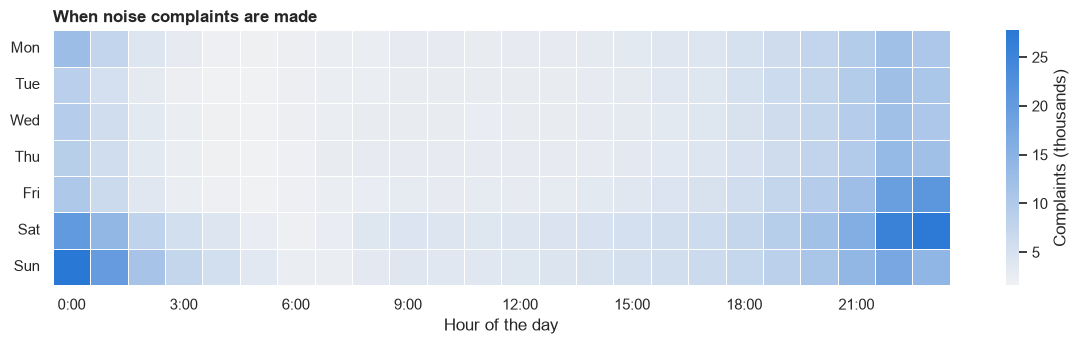

In [9]:
fig = P.plot_hour_weekday(findings, "noise"); P.save(fig, "street_timing_noise")

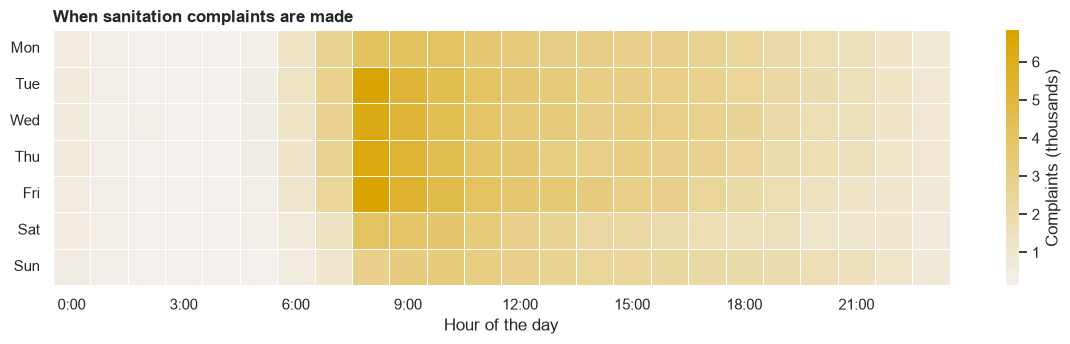

In [10]:
fig = P.plot_hour_weekday(findings, "sanitation"); P.save(fig, "street_timing_sanitation")

In [11]:
timing = pd.concat({g: pd.DataFrame(t["by_type"]).T for g, t in findings["q3_timing"].items()})
timing.columns = ["complaints", "share_at_night", "share_on_weekend"]
print({g: f"night {t['night_share']:.0%}, weekend {t['weekend_share']:.0%}" for g, t in findings["q3_timing"].items()})
timing

{'noise': 'night 50%, weekend 41%', 'sanitation': 'night 9%, weekend 23%'}


complaints  share_at_night  \
noise      Loud Music/Party                 514,819.00            0.57   
           Banging/Pounding                 187,937.00            0.40   
           Loud Talking                     112,634.00            0.52   
           Car/Truck Music                   36,263.00            0.49   
           Construction Before/After Hours   28,566.00            0.45   
           Car/Truck Horn                    16,850.00            0.33   
           Engine Idling                     16,821.00            0.42   
           Construction Equipment            13,218.00            0.10   
sanitation Dirty Condition                  117,123.00            0.10   
           Missed Collection                 72,030.00            0.03   
           Illegal Dumping                   69,667.00            0.08   
           Rodent                            51,671.00            0.17   
           Residential Disposal Complaint    27,560.00            0.12   
           Litter Basket Request              7,271.00            0.09   
           Litter Basket Complaint            2,679.00            0.13   

                                            share_on_weekend  
noise      Loud Music/Party                             0.49  
           Banging/Pounding                             0.32  
           Loud Talking                                 0.33  
           Car/Truck Music                              0.44  
           Construction Before/After Hours              0.30  
           Car/Truck Horn                               0.28  
           Engine Idling                                0.28  
           Construction Equipment                       0.15  
sanitation Dirty Condition                              0.23  
           Missed Collection                            0.27  
           Illegal Dumping                              0.21  
           Rodent                                       0.21  
           Residential Disposal Complaint               0.20  
           Litter Basket Request                        0.20  
           Litter Basket Complaint                      0.26

## 4. Persistence: do hotspots stay hotspots?
Each dot is one 100 m cell: its complaints in January–October 2025 against January–October 2026 (log scales). A **hotspot** is a cell in the city's top 10%. If hotspots were random, about 10% of 2025's would still be hotspots in 2026 (the *chance level*).

In [12]:
q4 = pd.DataFrame(findings["q4_persistence"]).T
q4[["cells_with_complaints", "spearman", "hotspots_2025", "still_hotspot_2026", "chance_level"]]

,cells_with_complaints,spearman,hotspots_2025,still_hotspot_2026,chance_level
noise,"24,487.00",0.73,"2,810.00",0.66,0.10
sanitation,"24,384.00",0.51,"2,869.00",0.52,0.11


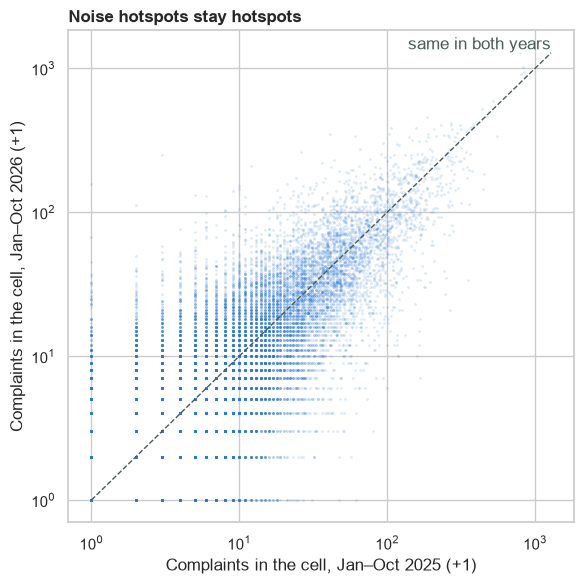

In [13]:
fig = P.plot_persistence(cells, "noise"); P.save(fig, "street_persistence_noise")

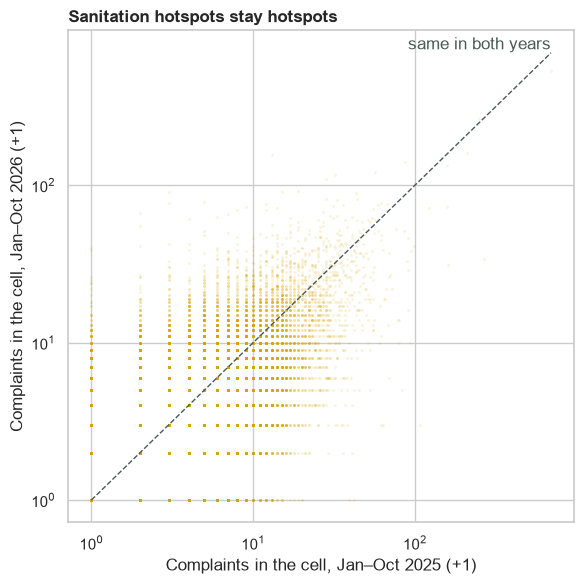

In [14]:
fig = P.plot_persistence(cells, "sanitation"); P.save(fig, "street_persistence_sanitation")

## 5. Two buildings, side by side
The app's Explore page does this for any two buildings on the map. Here: two apartment buildings a few streets apart. `StreetIndex` finds every complaint within 100 m of each one, ranks it against all apartment buildings in its community district, and `compare_report()` writes the paragraph. Every sentence is chosen by a fixed rule from the numbers, so each one can be traced back to the data.

In [15]:
index = street.StreetIndex(complaints, buildings)
pa, pb, text = street.compare_addresses(index, "235 East 92nd Street, Manhattan", "150 East 93rd Street, Manhattan")
print(f"A: {pa['name']}   B: {pb['name']}   ({street.distance_m(pa, pb):,.0f} m apart)\n")
print(text)
print("\n" + street.CAVEAT)

A: 203 East 92 Street   B: 135 East 93 Street   (242 m apart)

These two buildings, 242 meters apart in Manhattan Community District 8, are a trade-off: 135 East 93 Street is quieter, while 203 East 92 Street is cleaner. 203 East 92 Street gets about 84% more noise complaints than 135 East 93 Street (37 versus 20 a year), mostly loud music/party in both places, with 62% of 203 East 92 Street's and 38% of 135 East 93 Street's at night. 135 East 93 Street gets about 60% more sanitation complaints than 203 East 92 Street (13 versus 8 a year), mostly dirty condition around 203 East 92 Street and missed collection around 135 East 93 Street.

Based on NYC 311 complaints within 100 m, January 2025 to October 2026; repeat calls about the same thing at the same address on the same day count once. Complaints are reports, not measured noise or dirt, and some neighborhoods report more than others.


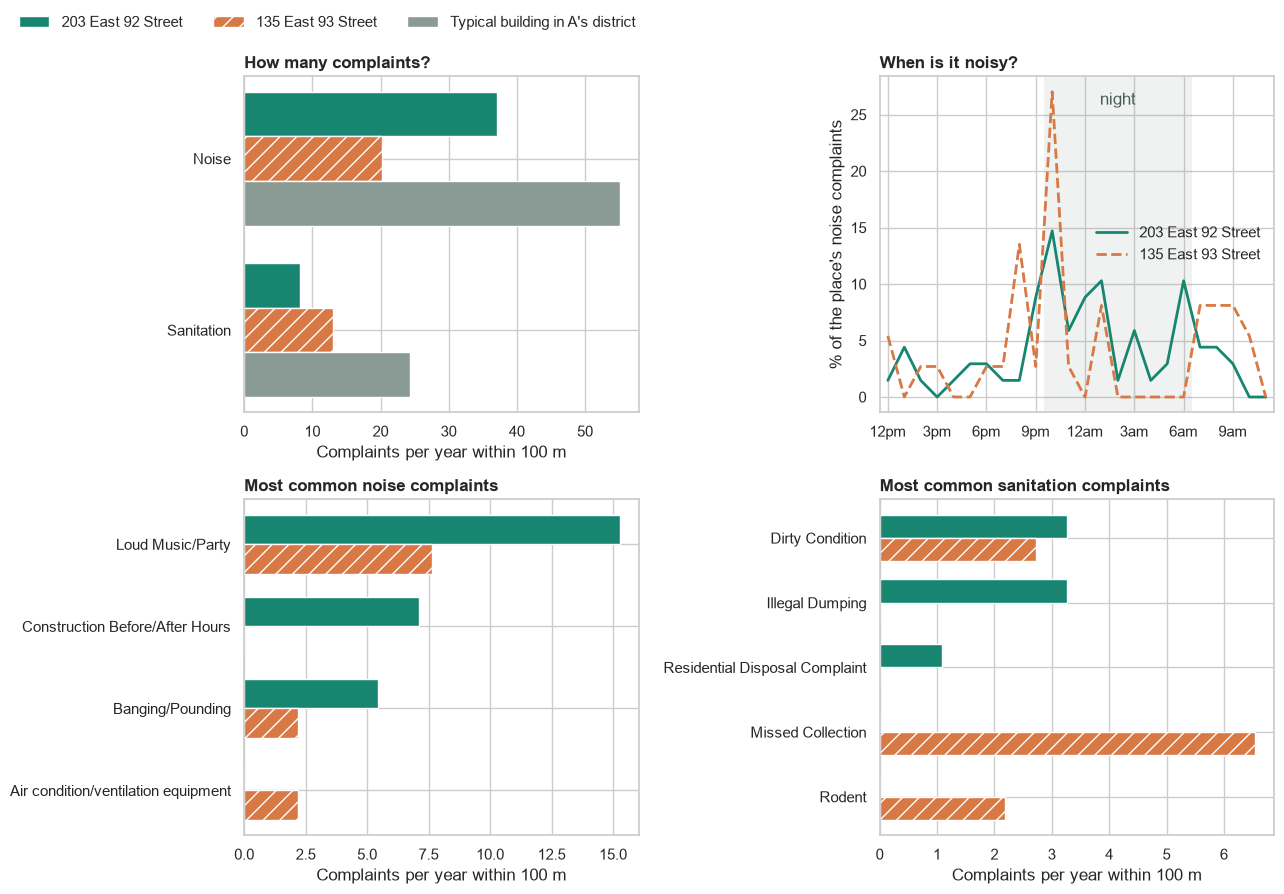

In [16]:
fig = P.plot_compare(pa, pb, pa["name"], pb["name"]); P.save(fig, "street_compare_example")

A second pair, in Brooklyn:

In [17]:
pa2, pb2, text2 = street.compare_addresses(index, "300 Linden Boulevard, Brooklyn", "100 Martense Street, Brooklyn")
print(f"A: {pa2['name']}   B: {pb2['name']}   ({street.distance_m(pa2, pb2):,.0f} m apart)\n")
print(text2)

A: 300 Linden Boulevard   B: 102 Martense Street   (629 m apart)

These two buildings, 629 meters apart in Brooklyn Community District 17, are not alike: 102 Martense Street looks like the better choice for quiet, clean streets. 300 Linden Boulevard gets about four times as many noise complaints as 102 Martense Street (177 versus 47 a year), mostly loud music/party in both places, about 51% of it at night. 300 Linden Boulevard gets about twice as many sanitation complaints as 102 Martense Street (29 versus 13 a year), mostly missed collection around 300 Linden Boulevard and dirty condition around 102 Martense Street. 300 Linden Boulevard was a noise hotspot (top 10% of its district) in both 2025 and 2026. 300 Linden Boulevard has been getting cleaner: 30 sanitation complaints in January–October 2025, 20 in 2026.


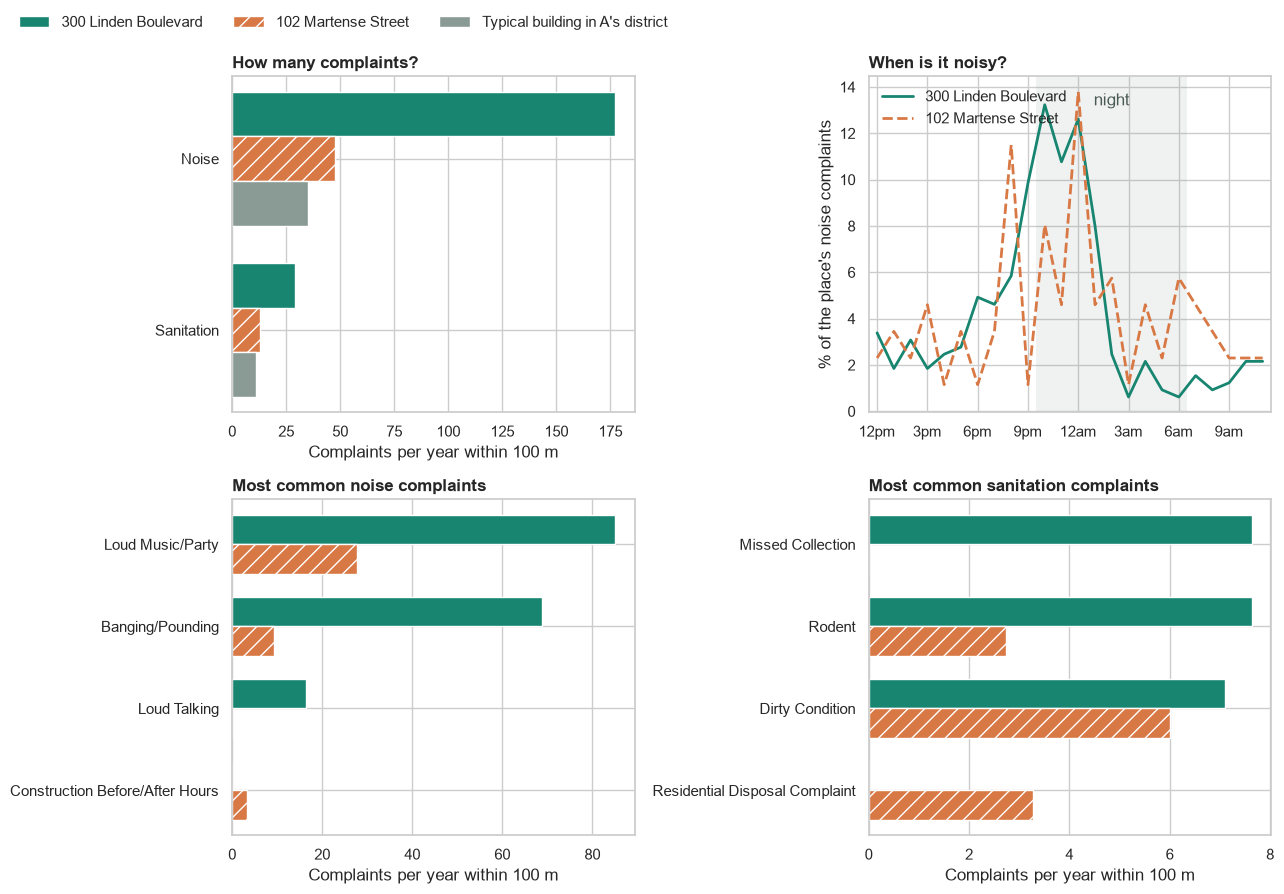

In [18]:
fig = P.plot_compare(pa2, pb2, pa2["name"], pb2["name"])

## Conclusions
Based on 1.34 million noise and sanitation complaints (0.99 million noise, 0.35 million sanitation; repeat calls about the same thing, at the same place, on the same day counted once) from January 2025 to October 2026, compared across 27,841 cells of 100 m × 100 m that contain an apartment building.

**1. District averages hide most of the difference.** 72% of the variation in noise complaints between cells, and 82% for sanitation, is *within* community districts, not between them. Knowing the district says little about a particular street.

**2. The next block over can be very different.** Two cells side by side differ on average by a factor of about **2.9 for noise** and **2.2 for sanitation**. That is only 13% (noise) and 10% (sanitation) smaller than the gap between two *random* cells in the same district. By about 1 km, neighbors are no more alike than random cells in the district. This is the 100-meter inequality: a street's noise and cleanliness are mostly local.

**3. Noise is a night and weekend problem; sanitation is a weekday-morning one.** Half of all noise complaints (50%) come between 10pm and 7am; they peak around 10pm, and most of all on Friday and Saturday nights. Loud music and parties are 52% of noise complaints. Only 10% of sanitation complaints come at night; they peak around 8am on weekdays, when people go out and find the street dirty or the collection missed.

**4. Hotspots last, especially for noise.** 66% of 2025's noise hotspots (the top 10% of cells) were still hotspots in 2026, against about 10% expected by chance (rank correlation 0.73). For sanitation it was 52% (0.51), so dirty streets change more from year to year than noisy ones.

**For a renter:** the noise level of a street is a stable, local trait that a district average or a borough reputation won't reveal, but 311 data can. The app shows it for any two buildings.


## Limitations
- **A complaint is a report, not a measurement.** Some residents call 311 much more readily than others, so a quiet-looking block may just report less.
- **One caller can file many complaints.** One Bronx address had about 120,000 "Loud Music/Party" calls in the raw data. Cleaning counts repeat calls about the same thing, at the same location, on the same day only once, but a single persistent caller can still make a cell look like a hotspot.
- **Cells and the 100 m radius are a choice.** Another size would change the exact numbers; `config.STREET_CELL_M` and `config.STREET_RADIUS_M` make that easy to test.
- **2026 covers January–October only**, so years are compared on the same ten months.